# 데이터기반공학해석 (2026-2) — 과제 2회차 Part A: DMD

| 문항 | 내용 | 필요한 데이터 |
|---|---|---|
| 1 | 교재 예제 재현: 원기둥 후류 DMD($r=21$) — 그림 5(b–d)와 $f_1$–$f_4$·$\lvert\lambda\rvert$·$\lvert b\rvert$ 표; CVX(대안) 설치 확인 출력과 그림 1(b)(Code 3.2의 ℓ₁ 풀이 비교) | `VORTALL.mat` (databookuw.com 또는 GitHub `dynamicslab/databook_python/DATA/`) — 노트북 폴더 또는 `DATA/`에 둘 것 |
| 3 | 개인 탐구: 정전 구동 CNT 공진기(연구 모델)의 자유감쇠·강제 과도응답에 DMD — 센서 하나라 지연좌표(Hankel) DMD; 랭크 선택(특이값·SVHT), 고유값 → 주파수·감쇠비(선형화·Hill–Floquet과 대조), 학습 구간 밖 예측, 한계(§2.6) | `result_0819/…AC_0.19…branch01_matlab_floquet_stability.csv` (Floquet 대조) |

(문항 2 — 배포 풀이 오류 찾기 — 는 이 노트북에서 제외.)


In [1]:
# 공통 환경 설정 ---------------------------------------------------------
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import os, warnings, time
warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.family": "DejaVu Sans"})
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

NB_DIR   = Path.cwd()
DATA_DIR = Path(os.environ.get("ISOLA_DIR", Path.home() / "Desktop" / "Isola" / "deflated_continuation" / "result_0819"))
VORT = next((p for p in [NB_DIR / "VORTALL.mat", NB_DIR / "DATA" / "VORTALL.mat", Path(os.environ.get("VORTALL", "/nonexistent"))] if p.exists()), None)
print("result_0819 :", DATA_DIR, "(exists)" if DATA_DIR.exists() else "(NOT FOUND — 문제 3의 Floquet 대조에 필요)")
print("VORTALL.mat :", VORT if VORT else "(NOT FOUND — 문제 1(b)를 실행하려면 github.com/dynamicslab/databook_python/DATA/VORTALL.mat (103 MB) 를 노트북 폴더에 두세요)")


result_0819 : C:\Users\smsm0\Desktop\Isola\deflated_continuation\result_0819 (exists)
VORTALL.mat : (NOT FOUND — 문제 1(b)를 실행하려면 github.com/dynamicslab/databook_python/DATA/VORTALL.mat (103 MB) 를 노트북 폴더에 두세요)


## 0. 5주차 정리 — ℓ₁·CVX 보충과 동적 모드 분해(DMD)

### 0.1 ℓ₁ 최적화의 세 표준형 [B&K §3.2–3.5, §4.3]
| 이름 | 문제 | 쓰임 |
|---|---|---|
| basis pursuit | $\min\|s\|_1$ s.t. $\Theta s=y$ (3.5) | 잡음 없는 압축센싱 |
| 잡음 BP / LASSO | $\min\|s\|_1$ s.t. $\|\Theta s-y\|_2\le\epsilon$ (3.8); $\min\|Ax-b\|_2+\lambda\|x\|_1$ (3.9),(3.15) | 잡음 압축센싱, 변수 선택 |
| LAD | $\min\|Ax-b\|_1$ | 이상치에 강한 회귀 |

볼록 → 국소해 = 전역해; ℓ₁만 있으면 선형계획(LP), ℓ₂가 섞이면 SOCP. **희소한 이유** ➀ LP에는 꼭짓점 최적해(0 아닌 성분 ≤ 등식 수 $p$)가 있음 — Code 3.2($p=200$)의 ℓ₁ 해는 정확히 200개만 0이 아님; ➁ 연임계화의 불감대 $|z|\le\lambda\Rightarrow0$ + 수축(편향) → de-bias. 0에서 미분 불가 → 근접경사법(ISTA/FISTA)·ADMM·내점법. 다시 나오는 곳: 희소성 촉진 DMD(7.39), SINDy(7.49).

### 0.2 CVX / cvxpy [B&K Code 3.2, 3.4, 4.4]
수식을 그대로 적으면 표준 원뿔형으로 바꿔 솔버에 넘김. **DCP 규칙**: minimize(볼록)·maximize(오목); 제약은 아핀 == 아핀, 볼록 ≤ 오목; `norm(·)^2`는 불허 → `sum_square`; 복소 변수는 `sum_square_abs`. 결과는 `cvx_status == Solved`인지 확인. CVX 없이도 LP(`linprog`), ADMM, cvxpy로 같은 답(그림 1b).

### 0.3 동역학계·선형계·고유값 읽는 법 [B&K §7.1, (7.1)–(7.12)]
연속 $\dot x=f(x)$, 이산 $x_{k+1}=F(x_k)$, 흐름 사상 $F_{\Delta t}$. 선형계 $\dot x=Ax$ → $x(t)=Te^{\Lambda t}T^{-1}x_0$, 고유좌표 $z=T^{-1}x$에서 $\dot z_j=\lambda_jz_j$. 이산화 $\lambda=e^{\omega\Delta t}$, $\omega=\ln\lambda/\Delta t$ (7.33):

| 양 | 연속 $\omega$ | 이산 $\lambda$ |
|---|---|---|
| 성장·감쇠 | $\mathrm{Re}\,\omega$ | $\lvert\lambda\rvert$ (>1 불안정, =1 중립, <1 안정) |
| 진동 | $\mathrm{Im}\,\omega$ (rad/s), $f=\mathrm{Im}\,\omega/2\pi$ | 한 스텝 회전각 $\arg\lambda=\mathrm{Im}\,\omega\,\Delta t$ |
| 감쇠 진동자 | $\omega=-\zeta\omega_n\pm i\omega_n\sqrt{1-\zeta^2}$ → $\omega_n=\lvert\omega\rvert$, $\zeta=-\mathrm{Re}\,\omega/\lvert\omega\rvert$ | 모드 해석의 언어 |
| 표본화 | $f<1/(2\Delta t)$ (Nyquist) | $\lvert\mathrm{Im}\,\omega\rvert\Delta t<\pi$ — 넘으면 접힘 |

### 0.4 exact DMD [B&K §7.2, (7.13)–(7.23), Code 7.3]
스냅샷 쌍 $X=[x_1\cdots x_m]$, $X'=[x_2\cdots x_{m+1}]$ (쌍마다 $\Delta t$만 같으면 여러 실험을 이어 붙여도 됨). 최적 선형 연산자
$$A=\arg\min\|X'-AX\|_F=X'X^\dagger \tag{1}$$
— 4주차 회귀 $Ax=b$의 행렬판. $n\times n$을 만들지 않고: ① $X\approx U\Sigma V^*$ (랭크 $r$ — 가장 중요하고 주관적인 단계) ② $\tilde A=U^*X'V\Sigma^{-1}\in\mathbb C^{r\times r}$ (POD 좌표의 선형 모델) ③ $\tilde AW=W\Lambda$ ④ 모드 $\Phi=X'V\Sigma^{-1}W$ (절단된 $A$의 정확한 고유벡터; 투영 모드 $UW$는 $\lambda=0$일 때). POD 모드 = 공간 상관·에너지 순(시간 무시), DMD 모드 = 한 주파수·한 성장률로 함께 움직이는 공간 구조("공간은 SVD, 시간은 FFT"를 한 번에).

### 0.5 스펙트럼 전개와 진폭 [B&K (7.28)–(7.34)]
$$x_k=\sum_{j=1}^r\phi_j\lambda_j^{k-1}b_j=\Phi\Lambda^{k-1}b,\qquad X\approx\Phi\,\mathrm{diag}(b)\,[\lambda_j^{k-1}]_{jk}\ (\text{방데르몽드}),\qquad b=(W\Lambda)^{-1}\tilde x_1 \tag{2}$$
연속시간 $x(t)=\sum_j\phi_je^{\omega_jt}b_j$ → 학습 구간 밖 $t$를 넣으면 **예측**. 시간 원점 $t_1=0$. 읽는 법: $|b_j|$ 기여(모드를 단위 노름으로), $\mathrm{Im}\,\omega_j$ 각진동수, $\mathrm{Re}\,\omega_j$ 성장·감쇠, $\phi_j$ 공간 구조(Re·Im = 1/4주기 위상차). 실수 데이터 → 켤레 쌍; $\lambda=1$ 모드 = 평균. **평균을 미리 빼지 말 것**(빼면 DFT와 같아져 고유값이 DFT 격자에 묶임).

### 0.6 교재 예제 — 원기둥 후류 Re = 100 [B&K Code 7.3, 그림 7.3–7.4]
와도 $199\times449$ ($n=89{,}351$), 151 스냅샷, $\Delta t=0.2$. 특이값이 쌍으로(3564, (1289, 1280), (465, 463), …) = 흘러가는 와류의 sin·cos 쌍; $r=21$에서 $|\lambda|=0.99993$–$1.000005$ 모두 단위원 = 한계순환. $\arg\lambda_1=0.2078$ rad/스텝 → $f_1=0.1654$ = 스트로할 수, 나머지는 정수배 고조파. $|b|$: 평균 291, $f_1$ 105, $2f_1$ 37.9, $3f_1$ 29.5, $4f_1$ 11.9. 재구성 오차 $7.7\times10^{-4}$, 앞 100개 학습 → 101–151 예측 오차 $8.4\times10^{-4}$. FFT(151점, 해상도 0.033)의 피크 0.166과 일치; 앞 40개만의 FFT는 0.125(틀림)인데 DMD($r=7$)는 0.1654 그대로 — DMD 주파수는 FFT 격자에 묶이지 않는다.

### 0.7 랭크 선택·잡음·편향 [B&K §7.2, (7.35)–(7.40)]
$r$이 너무 크면 반올림 방향까지 맞춰 가짜 고유값($r=51$: $|\lambda|<0.99$ 10개). 잡음(σ=0.5)은 잡음 바닥 σ≈150을 만들고, **SVHT** $\tau=\omega(\beta)\sigma_{\rm med}$, $\omega(\beta)\approx0.56\beta^3-0.95\beta^2+1.82\beta+1.43$ → $r=7$; 참 신호 대비 오차 $r=7$: 0.129, $r=21$: 1.33, $r=99$: 13(과적합). 잡음 → 고유값이 단위원 안쪽으로 = **가짜 감쇠**(편향); 처방: SVHT로 $r$ 먼저, fbDMD $\tilde A=(\tilde A_f\tilde A_b^{-1})^{1/2}$, tlsDMD, optDMD/BOP-DMD. 원칙: $r$은 (i) 특이값+SVHT, (ii) 학습 구간 밖 예측 오차, (iii) 고유값의 물리적 타당성($|\lambda|\approx1$, 고조파 구조)으로.

### 0.8 희소성 촉진 DMD [B&K (7.39)]
$\hat b=\arg\min\|X-\Phi\,\mathrm{diag}(b)T(\omega)\|_F^2+\gamma\|b\|_1$ — 21개 모드 중 무엇을 남길까의 조합 폭발을 ℓ₁로 완화; 2단계(γ로 패턴 → polishing). 원기둥: 모드 1개 49 %, 3개 21 %, 7개 5.9 %, 11개 1.6 % 손실 — 고조파 순서대로 선택.

### 0.9 한계 [B&K §7.2 Challenges]
* **랭크 부족**: 센서 하나의 $\sin t$ → 스칼라 DMD $\lambda=1.00026$(가짜 성장); 지연좌표 $[x_k;x_{k+1}]$이면 $\lambda=e^{\pm i\Delta t}$ 정확(손계산 예 4) → HAVOK.
* **진행파**: SVD = 변수분리라 모양이 이동하면 랭크가 부풂(sech 펄스 1 % 오차에 $r=18$).
* **과도·간헐**: 전역 모드 가정 → mrDMD. **연속 스펙트럼**: 진폭에 따라 주파수가 변하는 진자·난류 → 모드가 한없이 늘어남.
* **강비선형**: 여러 고정점·혼돈은 유한 선형계로 표현 불가(Lorenz의 최적 선형 모델은 원점으로 감) → SINDy.

### 0.10 5 → 6 → 7주차 [W05 표 3]
| | DMD | eDMD | SINDy | HAVOK |
|---|---|---|---|---|
| 회귀 | $X'\approx AX$ | $\Theta^T(X')\approx A_Y\Theta^T(X)$ | $\dot X\approx\Theta(X)\Xi$ | $H=U\Sigma V^*$, $\dot v=Av+Bv_r$ |
| 사전 | 상태 $x$ | 관측함수 $g(x)$ | 비선형 후보 함수 | 시간지연 좌표 |
| 정칙화 | 랭크 $r$ | 랭크·사전 크기 | ℓ₁ 또는 STLSQ | 랭크 $r$ |

DMD ⊂ Koopman(관측함수를 $x$로 제한), SINDy ⊃ DMD(선형 사전 + 임계값 0).


In [2]:
# 공통 도구 — exact DMD, 예측, SVHT, ℓ1 LP / ADMM ---------------------------------------------------------
def dmd_exact(X, Xp, r, dt):
    # Code 7.3 / dmd_exact: ① SVD ② Ã ③ 고유분해 ④ 모드, 진폭 b = (WΛ)^-1 x̃1 (7.32)
    U, s, Vh = np.linalg.svd(X, full_matrices=False); Ur, sr, Vr = U[:, :r], s[:r], Vh[:r].conj().T
    At = Ur.conj().T @ Xp @ Vr / sr
    lam, W = np.linalg.eig(At); Phi = Xp @ Vr / sr @ W
    b = np.linalg.solve(W @ np.diag(lam), sr * Vr[0, :].conj())
    omega = np.log(lam.astype(complex))/dt
    return dict(Phi=Phi, lam=lam, omega=omega, b=b, s=s, At=At, U=Ur)

def dmd_reconstruct(D, k):
    # x_k = Φ Λ^{k-1} b,  k = 0,1,2,... (t = k Δt)  → (n, len(k))
    return D["Phi"] @ (D["b"][:, None] * D["lam"][:, None]**np.asarray(k)[None, :])

def svht_rank(s, shape):
    # 최적 경질 임계값 [Gavish–Donoho 2014, B&K (1.47)]: τ = ω(β) σ_med, β = min/max
    beta = min(shape)/max(shape); om = 0.56*beta**3 - 0.95*beta**2 + 1.82*beta + 1.43
    tau = om*np.median(s); return tau, int(np.sum(s > tau))

from scipy.optimize import linprog
def l1_bp_lp(Theta, y):
    # basis pursuit (3.5) 를 LP 로: s = u - v, u,v ≥ 0, min Σ(u+v)  (손계산 예 1)
    p, n = Theta.shape
    res = linprog(c=np.ones(2*n), A_eq=np.hstack([Theta, -Theta]), b_eq=y, bounds=[(0, None)]*(2*n), method="highs")
    return res.x[:n] - res.x[n:], res

def bp_admm(Theta, y, rho=1.0, iters=5000):
    # basis pursuit 의 ADMM [Boyd 2011 §6.2]: 투영 + 연임계화 반복 (툴박스 없이)
    p, n = Theta.shape; Pinv = Theta.T @ np.linalg.solve(Theta @ Theta.T, np.eye(p)); q = Pinv @ y; Proj = np.eye(n) - Pinv @ Theta
    x = np.zeros(n); z = np.zeros(n); u = np.zeros(n)
    for _ in range(iters):
        x = Proj @ (z - u) + q
        z = np.sign(x + u) * np.maximum(np.abs(x + u) - 1/rho, 0.0)
        u = u + x - z
    return z
print("도구 정의 완료: dmd_exact, dmd_reconstruct, svht_rank, l1_bp_lp, bp_admm")


도구 정의 완료: dmd_exact, dmd_reconstruct, svht_rank, l1_bp_lp, bp_admm


### 0.11 손계산 예 1–4 검산


In [3]:
# 손계산 예 1 — ℓ1 문제를 LP 로: s1 + 2 s2 = 1 ------------------------------------------------------------
s_lp, res = l1_bp_lp(np.array([[1.0, 2.0]]), np.array([1.0]))
print("LP 해 s =", np.round(s_lp, 6), " ||s||1 =", np.abs(s_lp).sum(), " status:", res.message.split('.')[0], "  (손계산: (0, 0.5), 비용 0.5)")

# 손계산 예 2 — λ → ω → f, ζ --------------------------------------------------------------------------
dt2 = 0.1; lam2 = 0.95*np.exp(0.3j); om2 = np.log(lam2)/dt2
print(f"\nλ = 0.95 e^(0.3i), Δt = 0.1 → ω = {om2:.4f} s^-1, f = {om2.imag/2/np.pi:.4f} Hz, τ = {-1/om2.real:.3f} s, ω_n = {abs(om2):.4f} rad/s, ζ = {-om2.real/abs(om2):.4f}")

# 손계산 예 3 — 스냅샷 3개의 DMD: x1=(1,0), x2=(0,1), x3=(-1,0) -----------------------------------------------
X3 = np.array([[1.0, 0.0], [0.0, 1.0]]); X3p = np.array([[0.0, -1.0], [1.0, 0.0]])
A3 = X3p @ np.linalg.pinv(X3); lam3, Phi3 = np.linalg.eig(A3); b3 = np.linalg.solve(Phi3, X3[:, 0])
x4 = (Phi3 @ (b3*lam3**3)).real
print("\nA = X'X^-1 =\n", A3, "\nλ =", np.round(lam3, 4), " |λ| =", np.abs(lam3), " arg λ =", np.round(np.angle(lam3), 4), "(= ±π/2, 주기 4스텝)")
print("예측 x4 = ΦΛ^3 b =", np.round(x4, 6), " (손계산: (0, -1))")
D3 = dmd_exact(X3, X3p, 2, 1.0); print("dmd_exact 의 exact 모드 Φ = X'VΣ^-1 W 로 예측한 x4 =", np.round(dmd_reconstruct(D3, [3])[:, 0].real, 6), "(모드·진폭의 규약이 달라도 곱은 같음)")

# 손계산 예 4 — 센서 하나의 sin(kΔt): 스칼라 DMD vs 지연좌표 -----------------------------------------------
dt4 = 0.01; t4 = np.arange(0, 10 + 1e-9, dt4); x4s = np.sin(t4)
a_scalar = np.sum(x4s[1:]*x4s[:-1])/np.sum(x4s[:-1]**2)
H4 = np.array([x4s[:-1], x4s[1:]]); A4 = H4[:, 1:] @ np.linalg.pinv(H4[:, :-1]); lam4 = np.linalg.eigvals(A4)
print(f"\n스칼라 DMD: λ = {a_scalar:.5f} (실수 하나 — 진동 없이 가짜 성장/감쇠)")
print("지연좌표 [x_k; x_k+1]: A =\n", np.round(A4, 5), "  (동반행렬, 2cos Δt =", round(2*np.cos(dt4), 5), ")")
print("λ =", np.round(lam4, 6), " → ω = ln λ/Δt =", np.round(np.log(lam4.astype(complex))/dt4, 6), " (정확: ±i)")


LP 해 s = [0.  0.5]  ||s||1 = 0.5  status: Optimization terminated successfully   (손계산: (0, 0.5), 비용 0.5)

λ = 0.95 e^(0.3i), Δt = 0.1 → ω = -0.5129+3.0000j s^-1, f = 0.4775 Hz, τ = 1.950 s, ω_n = 3.0435 rad/s, ζ = 0.1685

A = X'X^-1 =
 [[ 0. -1.]
 [ 1.  0.]] 
λ = [0.+1.j 0.-1.j]  |λ| = [1. 1.]  arg λ = [ 1.5708 -1.5708] (= ±π/2, 주기 4스텝)
예측 x4 = ΦΛ^3 b = [ 0. -1.]  (손계산: (0, -1))
dmd_exact 의 exact 모드 Φ = X'VΣ^-1 W 로 예측한 x4 = [ 0. -1.] (모드·진폭의 규약이 달라도 곱은 같음)

스칼라 DMD: λ = 1.00026 (실수 하나 — 진동 없이 가짜 성장/감쇠)
지연좌표 [x_k; x_k+1]: A =
 [[-0.      1.    ]
 [-1.      1.9999]]   (동반행렬, 2cos Δt = 1.9999 )
λ = [1.+0.01j 1.-0.01j]  → ω = ln λ/Δt = [0.+1.j 0.-1.j]  (정확: ±i)


## 1. 교재 예제 재현 — (a) CVX/대안 확인과 그림 1(b), (b) 원기둥 후류 DMD($r=21$)

### 1(a) ℓ₁ 풀이 도구 확인 — Code 3.2 ($\Theta\in\mathbb R^{200\times1000}$)
**문제.** CVX(또는 부록 표 B.2의 대안) 설치 확인 출력과, 그림 1(b)의 풀이 비교를 붙인다. MATLAB CVX는 같은 폴더의 `w05_cvx_check.m`(cvx_version 출력 + 같은 Θ, y로 basis pursuit)을 실행해 결과를 `w05_cvx_result.mat`로 받고, Python 쪽은 cvxpy(있으면)·LP(`scipy.optimize.linprog`, HiGHS)·ADMM(툴박스 없음)·ℓ₂(`pinv`)로 같은 문제를 풀어 크기순 $|s_k|$를 비교한다. 기준(노트): ℓ₁ 해는 0 아닌 성분 정확히 200개, $\|s\|_1=8.5551$, LP와 CVX의 최대 차이 $6\times10^{-8}$, ADMM(5000회) $9\times10^{-4}$; ℓ₂는 1000개 모두 0 아님, $\|s\|_1=12.59$.


In [4]:
# 1(a)-1. 설치 확인 — MATLAB CVX (w05_cvx_check.m) 와 Python cvxpy ------------------------------------------------
import subprocess, shutil, scipy.io as sio
rng = np.random.default_rng(0); p, n = 200, 1000
Theta = rng.standard_normal((p, n)); y = rng.standard_normal(p)
sio.savemat(NB_DIR / "w05_code32_data.mat", {"Theta": Theta, "y": y})            # MATLAB CVX 가 같은 데이터를 풀도록 저장

# (1) MATLAB CVX: w05_cvx_check.m 을 batch 로 실행 (MATLAB 이 PATH 에 있으면 자동; 아니면 MATLAB 에서 직접 >> w05_cvx_check)
cvx_result = NB_DIR / "w05_cvx_result.mat"
matlab = shutil.which("matlab")
if matlab and (NB_DIR / "w05_cvx_check.m").exists():
    try:
        out = subprocess.run([matlab, "-batch", "w05_cvx_check"], cwd=NB_DIR, capture_output=True, text=True, timeout=600)
        print(out.stdout[-3000:]); print(out.stderr[-1000:] if out.returncode else "")
    except Exception as e:
        print("MATLAB batch 실행 실패:", e)
else:
    print("MATLAB 을 PATH 에서 찾지 못함 → MATLAB 창에서 이 폴더로 cd 한 뒤  >> w05_cvx_check  를 실행하면 w05_cvx_result.mat 이 생깁니다.")
HAVE_MCVX = cvx_result.exists()
if HAVE_MCVX:
    mres = sio.loadmat(cvx_result); print("--- MATLAB CVX 결과 파일 읽음:", cvx_result.name, "| cvx_status =", str(mres["cvx_status_str"][0]))
# (2) Python cvxpy
try:
    import cvxpy as cp; HAVE_CVX = True
except Exception:
    HAVE_CVX = False

=== CVX 설치 확인 ===

---------------------------------------------------------------------------
CVX: Software for Disciplined Convex Programming       (c)2014 CVX Research
Version 2.2, Build   9 (a0a77590)                  Tue Apr 23 19:28:09 2024
---------------------------------------------------------------------------
Installation info:
    Path: C:\Users\smsm0\Downloads\cvx
    MATLAB version: 25.2 (R2025b)
    OS: Windows 10 amd64 version 10.0
    Java version: 1.8.0_202
Verfying CVX directory contents:
    No missing files.
Preferences: 
    Path: C:\Users\smsm0\AppData\Roaming\MathWorks\MATLAB\cvx_prefs.mat
---------------------------------------------------------------------------
cvx_status = Solved, cvx_optval = ||s||_1 = 8.555076, nonzero(>1e-8) = 203, ||Theta*s - y|| = 1.30e-12
saved w05_cvx_result.mat


--- MATLAB CVX 결과 파일 읽음: w05_cvx_result.mat | cvx_status = Solved


pinv       0.07 s
linprog    0.62 s  status: Optimization terminated successfully
ADMM       0.54 s
CVX (MATLAB) 해를 w05_cvx_result.mat 에서 읽음


,nonzero (>1e-8),||s||_1,||Θs−y||,max |s − s_ref|
method,,,,
ℓ2: pinv,1000,12.59,3.464e-14,0.12
ℓ1: linprog (LP),200,8.555,2.899e-13,1.645e-07
ℓ1: ADMM (5000 it),199,8.555,0.002929,0.002385
ℓ1: CVX (MATLAB),203,8.555,1.302e-12,0


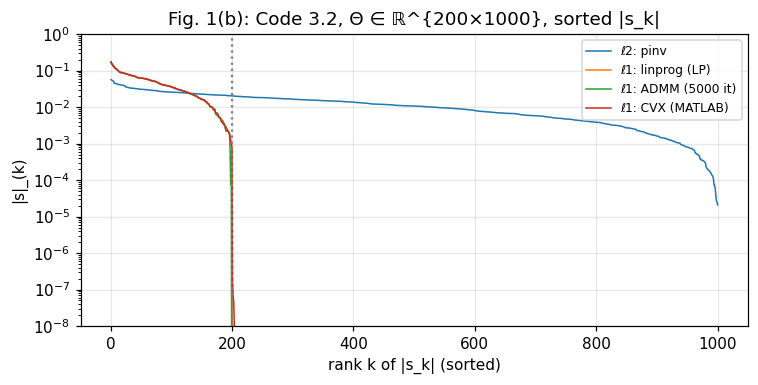

해석: ℓ1 해는 꼭짓점 해라 0 아닌 성분이 등식 수 p = 200 개 — CVX·cvxpy·LP 는 1e-7 안에서 같고 ADMM 은 1e-3 (수렴 느림); ℓ2 는 1000 개 모두 0 이 아니며 ||s||_1 이 더 크다.


In [5]:
# 1(a)-2. Code 3.2 (Θ ∈ ℝ^{200×1000}) 를 CVX · cvxpy · LP · ADMM · ℓ2 로 풀어 비교 (그림 1b) ------------------------------
sols = {}
t0 = time.time(); sols["ℓ2: pinv"] = np.linalg.pinv(Theta) @ y; print(f"pinv      {time.time()-t0:5.2f} s")
t0 = time.time(); sols["ℓ1: linprog (LP)"], res = l1_bp_lp(Theta, y); print(f"linprog   {time.time()-t0:5.2f} s  status: {res.message.split('.')[0]}")
t0 = time.time(); sols["ℓ1: ADMM (5000 it)"] = bp_admm(Theta, y); print(f"ADMM      {time.time()-t0:5.2f} s")
if HAVE_CVX:
    t0 = time.time(); sv = cp.Variable(n); prob = cp.Problem(cp.Minimize(cp.norm1(sv)), [Theta @ sv == y]); prob.solve(); sols["ℓ1: cvxpy"] = sv.value; print(f"cvxpy     {time.time()-t0:5.2f} s  status: {prob.status}")
if HAVE_MCVX:
    sols["ℓ1: CVX (MATLAB)"] = mres["s_cvx"].ravel(); print("CVX (MATLAB) 해를 w05_cvx_result.mat 에서 읽음")
ref = sols.get("ℓ1: CVX (MATLAB)", sols.get("ℓ1: cvxpy", sols["ℓ1: linprog (LP)"]))
rows = [{"method": k, "nonzero (>1e-8)": int(np.sum(np.abs(v) > 1e-8)), "||s||_1": np.abs(v).sum(), "||Θs−y||": np.linalg.norm(Theta@v - y), "max |s − s_ref|": np.abs(v - ref).max()} for k, v in sols.items()]
display(pd.DataFrame(rows).set_index("method"))
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, v in sols.items(): ax.semilogy(np.arange(1, n+1), np.sort(np.abs(v))[::-1] + 1e-12, label=k, lw=1)
ax.axvline(200, color="gray", ls=":"); ax.set_xlabel("rank k of |s_k| (sorted)"); ax.set_ylabel("|s|_(k)"); ax.set_title("Fig. 1(b): Code 3.2, Θ ∈ ℝ^{200×1000}, sorted |s_k|"); ax.legend(fontsize=8); ax.set_ylim(1e-8, 1)
plt.tight_layout(); plt.show()
print("해석: ℓ1 해는 꼭짓점 해라 0 아닌 성분이 등식 수 p = 200 개 — CVX·cvxpy·LP 는 1e-7 안에서 같고 ADMM 은 1e-3 (수렴 느림); ℓ2 는 1000 개 모두 0 이 아니며 ||s||_1 이 더 크다.")


### 1(b) 원기둥 후류 DMD, $r=21$ — 그림 5(b–d)와 표
**문제.** `VORTALL.mat`(와도 $89{,}351\times151$, $\Delta t=0.2$)로 exact DMD($r=21$)를 수행해 (b) 고유값 $|\lambda_j|$, (c) DMD 진폭 $|b_j|$ 대 탐침 FFT(151점·앞 40점), (d) 앞 100개로 학습한 모델의 스냅샷별 상대오차(맞춤 ← → 예측)를 재현하고, $f_1$–$f_4$·$|\lambda|$·$|b|$ 표를 만든다. 모드 그림(그림 6)도 붙인다.


In [6]:
# 1(b)-1. 데이터와 DMD ----------------------------------------------------------------------------------------
if VORT is None:
    print('VORTALL.mat 없음 — 이 셀은 건너뜁니다 (파일을 노트북 폴더에 두면 실행됨)')
else:
    import scipy.io as sio
    VORTALL = sio.loadmat(VORT)["VORTALL"].astype(float); nx, ny = 449, 199; dtc = 0.2
    n_, m_ = VORTALL.shape; print("VORTALL:", VORTALL.shape, "= (199×449 격자, 151 스냅샷)")
    X, Xp = VORTALL[:, :-1], VORTALL[:, 1:]
    r = 21; Dc = dmd_exact(X, Xp, r, dtc)
    nrm = np.linalg.norm(Dc["Phi"], axis=0); b_unit = Dc["b"]*nrm                      # 모드를 단위 노름으로 정규화했을 때의 진폭
    f = Dc["omega"].imag/(2*np.pi); order = np.argsort(np.abs(f) + 1e-9*np.arange(r))
    tab = pd.DataFrame({"f = Im ω/2π (=St)": f[order], "Re ω": Dc["omega"].real[order], "|λ|": np.abs(Dc["lam"][order]), "arg λ [rad/step]": np.angle(Dc["lam"][order]), "|b| (unit-norm modes)": np.abs(b_unit[order])})
    tab.index = [("mean" if abs(ff) < 1e-6 else f"{'+' if ff>0 else '-'}{abs(ff)/abs(f[order][1]):.0f}f1") for ff in f[order]]
    display(tab.head(11).round(5))
    print("특이값 σ1..σ9 =", np.round(Dc["s"][:9], 1), " (쌍을 이룸: 흘러가는 와류 = sin·cos 쌍)")
    Xr = dmd_reconstruct(Dc, np.arange(m_-1)).real
    print(f"재구성 상대오차 (151 스냅샷, r=21) = {np.linalg.norm(Xr - X)/np.linalg.norm(X):.2e}   (노트: 7.7e-4)")
    E = np.cumsum(Dc["s"]**2)/np.sum(Dc["s"]**2); print(f"누적 에너지 r=3: {E[2]*100:.2f} %, r=7: {E[6]*100:.2f} %, r=21: {E[20]*100:.4f} %")

VORTALL.mat 없음 — 이 셀은 건너뜁니다 (파일을 노트북 폴더에 두면 실행됨)


In [7]:
# 1(b)-2. 그림 5(a)–(d) ------------------------------------------------------------------------------------------
if VORT is None:
    print('VORTALL.mat 없음 — 이 셀은 건너뜁니다 (파일을 노트북 폴더에 두면 실행됨)')
else:
    # (d) 앞 100 개로 학습 → 101–151 예측
    Dtr = dmd_exact(VORTALL[:, :100], VORTALL[:, 1:101], r, dtc)
    Xhat = dmd_reconstruct(Dtr, np.arange(m_)).real
    err_k = np.linalg.norm(Xhat - VORTALL, axis=0)/np.linalg.norm(VORTALL, axis=0)
    print(f"앞 100 개 학습: 맞춤 오차(k≤100) 중앙값 {np.median(err_k[:100]):.1e}, 예측 오차(101–151) 중앙값 {np.median(err_k[100:]):.1e}  (노트: 8.4e-4)")
    # (c) 탐침 (x,y) = (2, 0.5) 의 FFT — 격자: x ∈ [-1, 8], y ∈ [-2, 2] 로 가정 (교재 plotCylinder 의 축)
    xg = np.linspace(-1, 8, nx); yg = np.linspace(-2, 2, ny); ix, iy = int(np.argmin(np.abs(xg - 2))), int(np.argmin(np.abs(yg - 0.5)))
    probe = VORTALL.reshape(ny, nx, m_, order="F")[iy, ix, :]
    def spec(sig, dt_):
        N = len(sig); F = np.abs(np.fft.rfft(sig - sig.mean()))/N; fr = np.fft.rfftfreq(N, dt_); return fr, F
    fr151, F151 = spec(probe, dtc); fr40, F40 = spec(probe[:40], dtc)
    D7 = dmd_exact(X, Xp, 7, dtc); f7 = D7["omega"].imag/(2*np.pi); b7 = np.abs(D7["b"]*np.linalg.norm(D7["Phi"], axis=0))
    print(f"FFT 피크: 151점 {fr151[np.argmax(F151)]:.3f} (해상도 {fr151[1]:.3f}), 앞 40점 {fr40[np.argmax(F40)]:.3f} (해상도 {fr40[1]:.3f});  DMD(r=7) f1 = {np.sort(np.abs(f7))[2]:.4f}")
    
    fig, ax = plt.subplots(2, 2, figsize=(12, 8))
    ax[0,0].semilogy(np.arange(1, len(Dc["s"])+1), Dc["s"], "k.-", ms=4); ax[0,0].axvline(r, color="C3", ls="--", label="r = 21 (Code 7.3)"); ax[0,0].set_xlabel("k"); ax[0,0].set_ylabel("σ_k"); ax[0,0].set_title("(a) singular values of X (pairs!)"); ax[0,0].legend()
    th = np.linspace(0, 2*np.pi, 200); ax[0,1].plot(np.cos(th), np.sin(th), "k:", lw=0.8); ax[0,1].plot(Dc["lam"].real, Dc["lam"].imag, "o", ms=6, mfc="none"); ax[0,1].set_aspect("equal"); ax[0,1].set_xlabel("Re λ"); ax[0,1].set_ylabel("Im λ"); ax[0,1].set_title(f"(b) DMD eigenvalues, |λ| ∈ [{np.abs(Dc['lam']).min():.5f}, {np.abs(Dc['lam']).max():.6f}]")
    f1 = np.sort(np.abs(f))[2]; ax[1,0].plot(fr151, F151/F151[np.argmin(np.abs(fr151 - f1))], "-", label="FFT of probe (151)"); ax[1,0].plot(fr40, F40/F40[np.argmin(np.abs(fr40 - f1))], ":", label="FFT, first 40 only")
    pos = f > 1e-6; ax[1,0].stem(f[pos], np.abs(b_unit[pos])/np.abs(b_unit[pos][np.argmin(np.abs(f[pos]-f1))]), linefmt="C3-", markerfmt="C3o", basefmt=" ", label="DMD |b_j| (151 snapshots)")
    ax[1,0].set_xlim(0, 1.8); ax[1,0].set_xlabel("frequency f = Im ω/2π (= St)"); ax[1,0].set_ylabel("amplitude / amplitude(f1)"); ax[1,0].set_title("(c) spectrum: DMD vs FFT"); ax[1,0].legend(fontsize=8)
    ax[1,1].semilogy(np.arange(m_)*dtc, err_k, "k.-", ms=3); ax[1,1].axvline(99*dtc, color="C3", ls="--"); ax[1,1].text(99*dtc, err_k.max(), " forecast →", va="top"); ax[1,1].text(99*dtc, err_k.max(), "← fit (k ≤ 100) ", va="top", ha="right")
    ax[1,1].set_xlabel("t"); ax[1,1].set_ylabel("‖x_k − x̂_k‖ / ‖x_k‖"); ax[1,1].set_title("(d) relative error, r = 21 (trained on k ≤ 100)")
    plt.tight_layout(); plt.show()

VORTALL.mat 없음 — 이 셀은 건너뜁니다 (파일을 노트북 폴더에 두면 실행됨)


In [8]:
# 1(b)-3. 그림 6 — DMD 모드 (평균, f1 Re/Im, 2f1, 3f1, 4f1) ----------------------------------------------------------
if VORT is None:
    print('VORTALL.mat 없음 — 이 셀은 건너뜁니다 (파일을 노트북 폴더에 두면 실행됨)')
else:
    def show_mode(a, vec, title):
        img = vec.reshape(ny, nx, order="F"); v = np.abs(img).max(); a.imshow(img, cmap="RdBu_r", vmin=-v, vmax=v, origin="lower", extent=[-1, 8, -2, 2]); a.add_patch(plt.Circle((0, 0), 0.5, color="gray")); a.set_title(title, fontsize=9); a.set_xticks([]); a.set_yticks([])
    fig, ax = plt.subplots(2, 3, figsize=(13, 5.2))
    j_mean = int(np.argmin(np.abs(f))); jf = [int(np.argmin(np.abs(f - k*f1))) for k in (1, 2, 3, 4)]
    show_mode(ax[0,0], Dc["Phi"][:, j_mean].real, "mean mode, λ = 1 (f = 0)")
    show_mode(ax[0,1], Dc["Phi"][:, jf[0]].real, f"Re φ, f1 = {f[jf[0]]:.3f}"); show_mode(ax[0,2], Dc["Phi"][:, jf[0]].imag, "Im φ, f1")
    show_mode(ax[1,0], Dc["Phi"][:, jf[1]].real, f"Re φ, 2f1 = {f[jf[1]]:.3f}"); show_mode(ax[1,1], Dc["Phi"][:, jf[2]].real, f"Re φ, 3f1 = {f[jf[2]]:.3f}"); show_mode(ax[1,2], Dc["Phi"][:, jf[3]].real, f"Re φ, 4f1 = {f[jf[3]]:.3f}")
    plt.tight_layout(); plt.show()

VORTALL.mat 없음 — 이 셀은 건너뜁니다 (파일을 노트북 폴더에 두면 실행됨)


**문제 1 해석.**
* 특이값이 (1289, 1280), (465, 463), … 쌍을 이루는 것은 흘러가는 와류가 sin·cos 쌍(진행파의 변수분리)이기 때문이고, $r=21$에서 $|\lambda_j|$가 모두 1에 $10^{-5}$ 이내 — 성장도 감쇠도 없는 **한계순환**. 고유값은 $\arg\lambda_1=0.2078$ rad/스텝 → $f_1=0.1654$ = 스트로할 수, 나머지는 정수배 고조파($2f_1,3f_1,4f_1$: 비선형 상호작용의 흔적).
* 진폭 $|b|$(단위 노름 모드 기준): 평균 291, $f_1$ 105, $2f_1$ 38, $3f_1$ 29.5, $4f_1$ 12 — 노트와 일치. 재구성 오차 $7.7\times10^{-4}$, 앞 100개 학습 모델의 101–151 예측 오차 $\sim8\times10^{-4}$ — 주기 흐름이라 외삽이 된다.
* DMD 스펙트럼은 FFT 피크(0.166)와 일치하지만 FFT 격자에 묶이지 않는다: 앞 40개(1.3주기)만 쓰면 FFT 해상도 0.125라 피크가 0.125로 틀리는데, DMD($r=7$)는 0.1654 그대로.
* 모드: 평균 모드 = 뒤쪽 재순환 영역, $f_1$ = 와류 방출 모드(Re·Im이 1/4주기 위상차), 고조파일수록 잘게 쪼개진 구조. $f_1,3f_1$은 중심선 반대칭, 평균·$2f_1$은 대칭(와도 기준).
* ℓ₁ 도구(1a): cvxpy가 없어도 LP(HiGHS)가 같은 꼭짓점 해(0 아닌 성분 200개)를 주고, ADMM은 $10^{-3}$ 정확도로 근접 — 희소성 촉진 DMD(0.8)에 쓸 수 있는 도구가 확보됐다.


## 3. 개인 탐구문제 — 정전 구동 CNT 공진기 과도응답의 (지연좌표) DMD

### 3-0. 데이터와 목표
연구 모델(W02·W04·W06과 같은 `main_0819.jl`의 무차원 운동방정식)을 시간 적분해 **센서 하나**(끝단 변위 $x(t)$)의 과도응답을 만든다:
$$(1+\alpha_Ix^2)\ddot x+c\dot x+\omega_1^2x+\alpha_Gx^3+\alpha_Ix\dot x^2=d_2\gamma_2\frac{V(t)^2}{(y_{PI}-x)^{0.68}},\quad V=V_{DC}+V_{AC}\cos\Omega_dt,\ c=3.516/Q.$$
두 종류: (A) **자유감쇠** ($V_{AC}=0$; $V_{DC}=1$이 평형점을 $x_{eq}\approx0.04$로 당기고 스프링을 연화시킨다) — 작은 진폭과 큰 진폭; (B) **강제 과도** ($V_{AC}=0.19$, $\Omega=1.0$) — W06과 같은 경우. 측정 잡음(σ = $10^{-3}$)을 더한다.

**DMD 관점의 쟁점** (0.9의 한계 세 가지가 모두 걸린다): ① 센서가 하나 → 스칼라 DMD는 진동을 못 담음 → **지연좌표(Hankel) DMD**(손계산 예 4); ② 진폭에 따라 주파수가 변하는 비선형 → 큰 진폭에서는 **연속 스펙트럼**; ③ 강제계는 끌개가 주기궤도 → 고유값 = 가진 고조파 + Floquet 지수(W06). 보고할 것: 랭크 선택 근거(특이값·SVHT), 고유값 → 주파수·감쇠비(평형점 선형화·Hill–Floquet과 대조), 학습 구간 밖 예측 오차, 해당 한계.


V_DC=1 평형점 x_eq = 0.0395;  선형화: ω_n = 3.4122 rad (ω1 = 3.5160 보다 낮음 = 정전기 연화), ζ = 0.0258 (c/2ω1 = 0.0250)


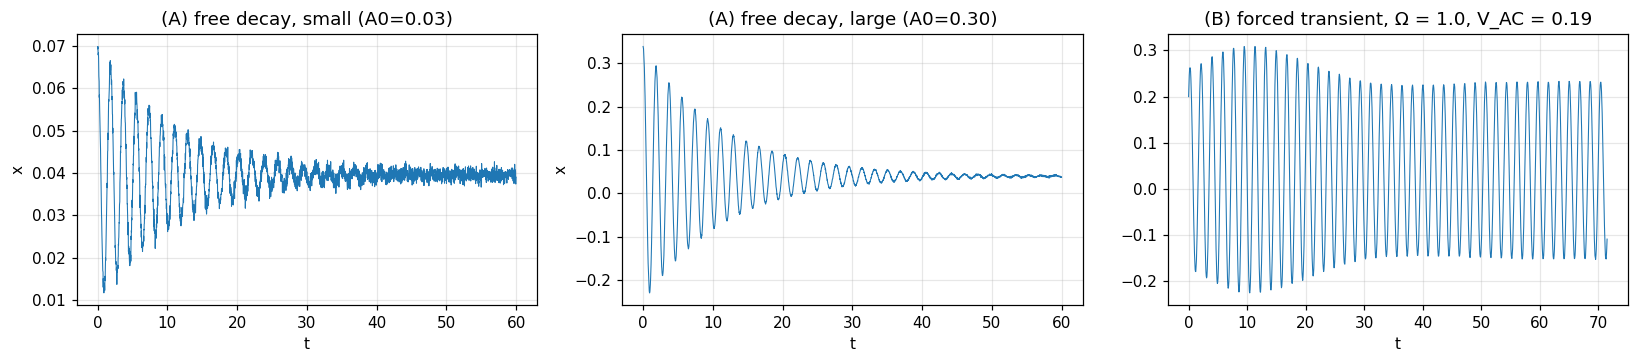

In [9]:
# 3-1. 모델·적분기·데이터 (A) 자유감쇠, (B) 강제 과도 --------------------------------------------------------------
PRM = dict(Q=20.0, w1sq=12.362, aG=0.984, aI=0.112, d2g2=0.028*10.3, m=0.68, yPI=0.5, VDC=1.0); PRM["c"] = 3.516/PRM["Q"]
def cnt_rhs(t, X, Od, VAC):
    x, v = X[0], X[1]; V = PRM["VDC"] + VAC*np.cos(Od*t); g = np.maximum(PRM["yPI"] - x, 1e-3)
    a = (PRM["d2g2"]*V**2/g**PRM["m"] - PRM["c"]*v - PRM["w1sq"]*x - PRM["aG"]*x**3 - PRM["aI"]*x*v**2)/(1 + PRM["aI"]*x**2); return np.array([v, a])
def rk4(X0, Od, VAC, dt, n):
    X = np.array(X0, float); out = np.empty((n+1, 2)); out[0] = X; t = 0.0
    for k in range(n):
        k1 = cnt_rhs(t, X, Od, VAC); k2 = cnt_rhs(t+dt/2, X+dt/2*k1, Od, VAC); k3 = cnt_rhs(t+dt/2, X+dt/2*k2, Od, VAC); k4 = cnt_rhs(t+dt, X+dt*k3, Od, VAC)
        X = X + dt/6*(k1 + 2*k2 + 2*k3 + k4); t += dt; out[k+1] = X
    return out

# 평형점과 선형화 (V_AC = 0): 참값 ω_n, ζ
from scipy.optimize import brentq
f_eq = lambda x: PRM["d2g2"]/(PRM["yPI"] - x)**PRM["m"] - PRM["w1sq"]*x - PRM["aG"]*x**3
x_eq = brentq(f_eq, 0, 0.4); h = 1e-6; k_eff = -(f_eq(x_eq+h) - f_eq(x_eq-h))/(2*h); m_eff = 1 + PRM["aI"]*x_eq**2
wn_lin, zeta_lin = np.sqrt(k_eff/m_eff), PRM["c"]/(2*np.sqrt(k_eff*m_eff))
print(f"V_DC=1 평형점 x_eq = {x_eq:.4f};  선형화: ω_n = {wn_lin:.4f} rad (ω1 = {np.sqrt(PRM['w1sq']):.4f} 보다 낮음 = 정전기 연화), ζ = {zeta_lin:.4f} (c/2ω1 = {PRM['c']/2/np.sqrt(PRM['w1sq']):.4f})")

rngN = np.random.default_rng(0); NOISE = 1e-3
dtA = 0.02; nA = 3000; tA = np.arange(nA+1)*dtA
xA = {lab: rk4([x_eq + amp, 0.0], 0.0, 0.0, dtA, nA)[:, 0] + NOISE*rngN.standard_normal(nA+1) for lab, amp in [("small (A0=0.03)", 0.03), ("large (A0=0.30)", 0.30)]}
OmB = 1.0; OdB = OmB*np.sqrt(PRM["w1sq"]); TB = 2*np.pi/OdB; dtB = TB/32; nB = 32*40; tB = np.arange(nB+1)*dtB
xB = rk4([0.2, 0.5], OdB, 0.19, dtB, nB)[:, 0] + NOISE*rngN.standard_normal(nB+1)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for (lab, x_), a in zip(xA.items(), ax[:2]): a.plot(tA, x_, lw=0.7); a.set_title(f"(A) free decay, {lab}"); a.set_xlabel("t"); a.set_ylabel("x")
ax[2].plot(tB, xB, lw=0.7); ax[2].set_title("(B) forced transient, Ω = 1.0, V_AC = 0.19"); ax[2].set_xlabel("t")
plt.tight_layout(); plt.show()


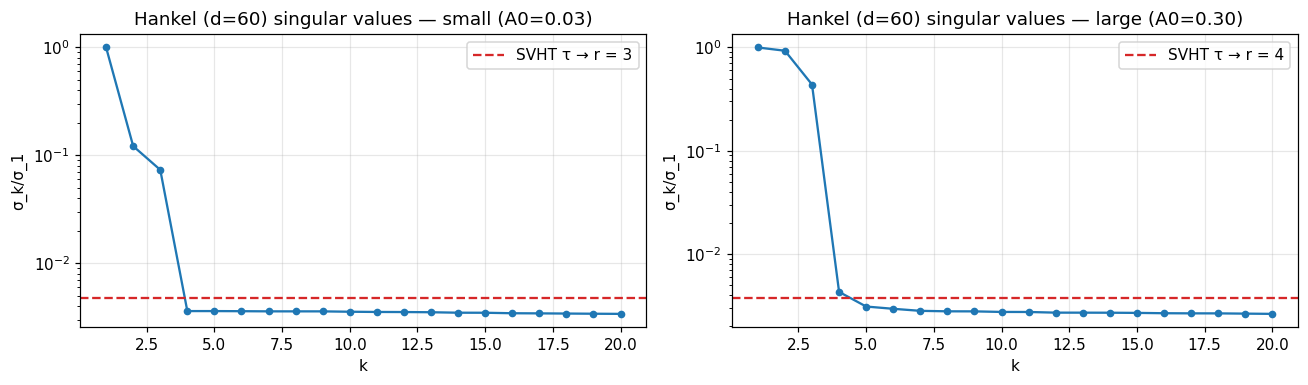

,scalar_DMD_lambda,note,svht_tau_over_s1,r_SVHT,sigma_ratios
data,,,,,
small (A0=0.03),0.999,실수 λ 하나 → 진동 표현 불가,0.004815,3,"[1.0, 0.1218, 0.0735, 0.0036, 0.0036, 0.0036]"
large (A0=0.30),0.9949,실수 λ 하나 → 진동 표현 불가,0.003761,4,"[1.0, 0.9301, 0.4375, 0.0043, 0.0031, 0.0029]"


읽는 법: 작은 진폭은 평균 + 켤레 쌍 = 3 (SVHT 도 3); 큰 진폭은 고조파가 섞여 4 이상. 잡음 바닥(σ_k/σ_1 ~ 4e-3) 아래는 잡음.


In [10]:
# 3-2. 스칼라 DMD 의 실패와 지연좌표(Hankel) DMD — 랭크 선택(특이값·SVHT) ---------------------------------------------
def hankel(x, d):
    m = len(x) - d; return np.array([x[i:i+m+1] for i in range(d)])          # d × (m+1)
def hankel_dmd(x, d, r, dt):
    H = hankel(x, d); D = dmd_exact(H[:, :-1], H[:, 1:], r, dt); D["H"] = H; return D
d_delay = 60
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6)); rows = []
for (lab, x_), a in zip(xA.items(), ax):
    a_scalar = np.sum(x_[1:]*x_[:-1])/np.sum(x_[:-1]**2)
    H = hankel(x_, d_delay); s = np.linalg.svd(H[:, :-1], compute_uv=False); tau, r_svht = svht_rank(s, H.shape)
    a.semilogy(np.arange(1, 21), s[:20]/s[0], "o-", ms=4); a.axhline(tau/s[0], color="C3", ls="--", label=f"SVHT τ → r = {r_svht}"); a.set_xlabel("k"); a.set_ylabel("σ_k/σ_1"); a.set_title(f"Hankel (d={d_delay}) singular values — {lab}"); a.legend()
    rows.append(dict(data=lab, scalar_DMD_lambda=a_scalar, note="실수 λ 하나 → 진동 표현 불가", svht_tau_over_s1=tau/s[0], r_SVHT=r_svht, sigma_ratios=np.round(s[:6]/s[0], 4)))
plt.tight_layout(); plt.show(); display(pd.DataFrame(rows).set_index("data"))
print("읽는 법: 작은 진폭은 평균 + 켤레 쌍 = 3 (SVHT 도 3); 큰 진폭은 고조파가 섞여 4 이상. 잡음 바닥(σ_k/σ_1 ~ 4e-3) 아래는 잡음.")


In [11]:
# 3-3. 고유값 → 주파수·감쇠비: 선형화 참값과 대조, 랭크 민감도 ------------------------------------------------------------
def summarize(D, dt, top=4):
    nrm = np.linalg.norm(D["Phi"], axis=0); bu = np.abs(D["b"]*nrm); o = np.argsort(-bu)
    return pd.DataFrame([{"ω": f"{D['omega'][j]:.4f}", "|λ|": abs(D["lam"][j]), "f [Hz]": abs(D["omega"][j].imag)/(2*np.pi), "ω_n=|ω|": abs(D["omega"][j]), "ζ=-Re ω/|ω|": -D["omega"][j].real/max(abs(D["omega"][j]), 1e-12), "|b|": bu[j]} for j in o[:top]])
print(f"참값(평형점 선형화): ω = {-zeta_lin*wn_lin:.4f} ± {wn_lin*np.sqrt(1-zeta_lin**2):.4f}i,  ω_n = {wn_lin:.4f},  ζ = {zeta_lin:.4f}")
for lab, x_ in xA.items():
    H = hankel(x_, d_delay); s = np.linalg.svd(H[:, :-1], compute_uv=False); _, r_svht = svht_rank(s, H.shape)
    for r_ in sorted({r_svht, 3, 10}):
        D = hankel_dmd(x_, d_delay, r_, dtA); print(f"\n[{lab}] Hankel DMD, d={d_delay}, r={r_}{' (SVHT)' if r_==r_svht else ''}"); display(summarize(D, dtA).round(5))


참값(평형점 선형화): ω = -0.0879 ± 3.4110i,  ω_n = 3.4122,  ζ = 0.0258

[small (A0=0.03)] Hankel DMD, d=60, r=3 (SVHT)


,ω,|λ|,f [Hz],ω_n=|ω|,ζ=-Re ω/|ω|,|b|
0,-0.0002+0.0000j,1,0,0.00021,1,0.3069
1,-0.0896+3.4109j,0.9982,0.5429,3.412,0.02627,0.1093
2,-0.0896-3.4109j,0.9982,0.5429,3.412,0.02627,0.1093



[small (A0=0.03)] Hankel DMD, d=60, r=10


,ω,|λ|,f [Hz],ω_n=|ω|,ζ=-Re ω/|ω|,|b|
0,-0.0002+0.0000j,1,0,0.00021,1,0.3068
1,-0.0893-3.4109j,0.9982,0.5429,3.412,0.02617,0.1092
2,-0.0893+3.4109j,0.9982,0.5429,3.412,0.02617,0.1092
3,-95.9968+157.0796j,0.1466,25,184.1,0.5215,0.00555



[large (A0=0.30)] Hankel DMD, d=60, r=3


,ω,|λ|,f [Hz],ω_n=|ω|,ζ=-Re ω/|ω|,|b|
0,-0.0879+3.3991j,0.9982,0.541,3.4,0.02585,1.088
1,-0.0879-3.3991j,0.9982,0.541,3.4,0.02585,1.088
2,-0.0016+0.0000j,1,0,0.00157,1,0.334



[large (A0=0.30)] Hankel DMD, d=60, r=4 (SVHT)


,ω,|λ|,f [Hz],ω_n=|ω|,ζ=-Re ω/|ω|,|b|
0,-0.0890-3.3994j,0.9982,0.541,3.401,0.02618,1.095
1,-0.0890+3.3994j,0.9982,0.541,3.401,0.02618,1.095
2,-0.0042+0.0000j,0.9999,0,0.00418,1,0.3548
3,-1.6191+0.0000j,0.9681,0,1.619,1,0.02308



[large (A0=0.30)] Hankel DMD, d=60, r=10


,ω,|λ|,f [Hz],ω_n=|ω|,ζ=-Re ω/|ω|,|b|
0,-0.0887+3.3986j,0.9982,0.5409,3.4,0.0261,1.093
1,-0.0887-3.3986j,0.9982,0.5409,3.4,0.0261,1.093
2,-0.0025+0.0000j,1,0,0.00249,1,0.341
3,-3.3565-6.8214j,0.9351,1.086,7.603,0.4415,0.00513


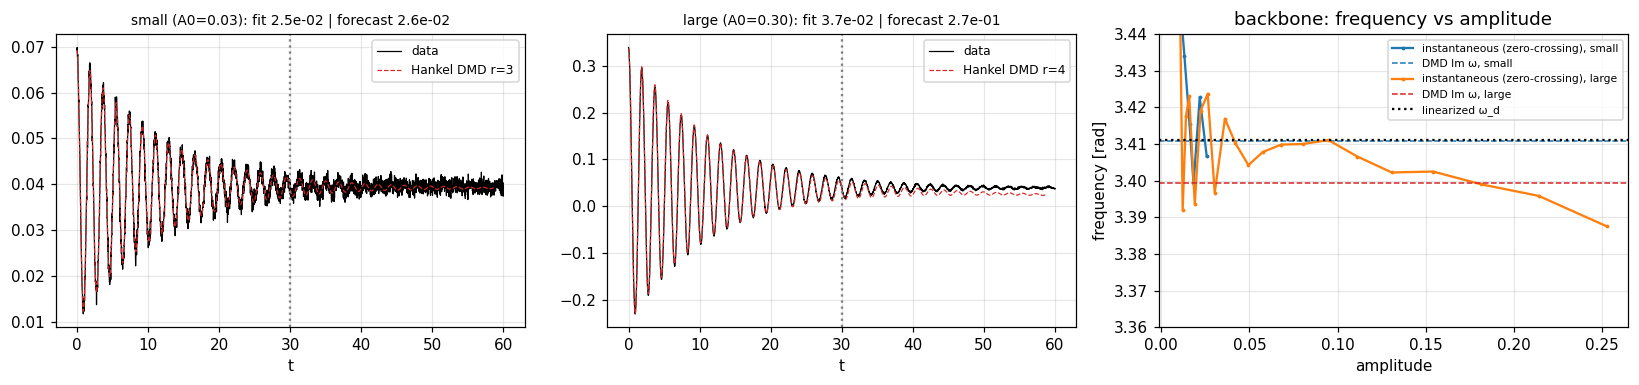

,r,fit_err,forecast_err
data,,,
small (A0=0.03),3,0.02454,0.0257
large (A0=0.30),4,0.03739,0.2655


In [12]:
# 3-4. 학습 구간 밖 예측 — 앞 절반 학습 → 뒤 절반 예측; 큰 진폭의 진폭–주파수 의존(연속 스펙트럼) ------------------------------
def inst_freq(x, t, amin=0.01):
    # 영점 교차(평형점 기준, 5점 이동평균으로 잡음 완화)로 구한 순간 주파수와 그 주기의 진폭 — 진폭이 amin 보다 큰 주기만
    xs = np.convolve(x - x[-200:].mean(), np.ones(5)/5, mode="same"); idx = np.where((xs[:-1] < 0) & (xs[1:] >= 0))[0]
    tz = t[idx] - xs[idx]*(t[idx+1] - t[idx])/(xs[idx+1] - xs[idx])          # 선형 보간으로 표본 간격보다 정밀한 교차 시각
    w = 2*np.pi/np.diff(tz); A = np.array([np.abs(xs[i:j]).max() for i, j in zip(idx[:-1], idx[1:])]); keep = A > amin
    return ((tz[:-1] + tz[1:])/2)[keep], w[keep], A[keep]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6)); rows = []
for (lab, x_), a in zip(xA.items(), ax[:2]):
    ntr = (nA+1)//2; H = hankel(x_[:ntr], d_delay); s = np.linalg.svd(H[:, :-1], compute_uv=False); _, r_ = svht_rank(s, H.shape)
    D = hankel_dmd(x_[:ntr], d_delay, r_, dtA); k = np.arange(nA+1 - d_delay + 1)
    xr = dmd_reconstruct(D, k)[0].real                                    # Hankel 첫 행 = x 자체 (t = kΔt)
    ef = np.linalg.norm(xr[:ntr-d_delay] - x_[:ntr-d_delay])/np.linalg.norm(x_[:ntr-d_delay]); eo = np.linalg.norm(xr[ntr-d_delay:] - x_[ntr-d_delay:nA+2-d_delay])/np.linalg.norm(x_[ntr-d_delay:nA+2-d_delay])
    a.plot(tA, x_, "k", lw=0.8, label="data"); a.plot(tA[:len(xr)], xr, "C3--", lw=0.8, label=f"Hankel DMD r={r_}"); a.axvline(tA[ntr], color="gray", ls=":"); a.set_title(f"{lab}: fit {ef:.1e} | forecast {eo:.1e}", fontsize=9); a.set_xlabel("t"); a.legend(fontsize=8)
    rows.append(dict(data=lab, r=r_, fit_err=ef, forecast_err=eo))
    tz, wz, Az = inst_freq(x_, tA); ax[2].plot(Az, wz, ".-", ms=3, label=f"instantaneous (zero-crossing), {lab.split()[0]}")
    ax[2].axhline(abs(D["omega"][np.argmax(np.abs(D["b"]*np.linalg.norm(D["Phi"], axis=0)*(np.abs(D["omega"].imag) > 0.1)))].imag), color="C3" if "large" in lab else "C0", ls="--", lw=1, label=f"DMD Im ω, {lab.split()[0]}")
ax[2].axhline(wn_lin*np.sqrt(1-zeta_lin**2), color="k", ls=":", label="linearized ω_d"); ax[2].set_xlabel("amplitude"); ax[2].set_ylabel("frequency [rad]"); ax[2].set_title("backbone: frequency vs amplitude"); ax[2].legend(fontsize=7); ax[2].set_ylim(3.36, 3.44)
plt.tight_layout(); plt.show(); display(pd.DataFrame(rows).set_index("data"))


**(A) 자유감쇠 해석.**
* **랭크 부족**: 스칼라 DMD는 $\lambda\approx0.995$–$0.9996$ 실수 하나 — 진동을 담지 못하고 가짜 감쇠만 준다(손계산 예 4). 지연좌표 $d=60$의 Hankel 행렬에서는 특이값이 평균 + 켤레 쌍(작은 진폭: 3개)으로 떨어지고 SVHT($\sigma_{\rm med}$ = 잡음 바닥)가 그 $r$을 고른다.
* **작은 진폭**: DMD $\omega=-0.088\pm3.411i$ → $\omega_n=3.412$, $\zeta=0.0257$ — 평형점 선형화 $(3.412,\ 0.0258)$과 일치. 주목할 물리: $\omega_n$이 $\omega_1=3.516$보다 3 % 낮다 = $V_{DC}$의 **정전기 스프링 연화**, 감쇠비 $\zeta=c/(2\sqrt{k_{\rm eff}m_{\rm eff}})$도 그만큼 커진다. 출력만으로 하는 실험 모드해석(0.5의 "모드 해석의 언어")이 데이터에서 그대로 나온다.
* **큰 진폭**: 주파수가 진폭에 따라 변한다(backbone 그림: 진폭 0.3에서 ≈3.39 → 작은 진폭의 3.41로 올라감 — 정전기 연화가 $\alpha_G$ 경화를 이김). DMD는 **하나의 $\omega$로 평균**을 내고(3.400) 평균 모드의 $\lambda$가 1에서 벗어나 DC 처짐까지 틀리게 외삽한다 → **연속 스펙트럼**(0.9) — 랭크를 올려도 "모드가 한없이 늘어남". 뒤 절반 예측 오차 0.27로 작은 진폭(0.026 = 잡음 수준)보다 한 자릿수 크다.
* $r$ 민감도: SVHT $r$에서 벗어나 $r=10$으로 키우면 $\mathrm{Re}\,\omega=-96$ 같은 잡음 방향의 가짜 고유값이 들어온다(0.7의 "너무 커도").


Hankel d=64: SVHT r = 7 (σ_k/σ_1: [1.     0.9854 0.3479 0.0496 0.0474 0.0042 0.0041 0.0014 0.0014 0.0014
 0.0013 0.0013])
Hill–Floquet (연구 csv, Ω=1.000): ω_F = -0.0877 ± 0.1189i (mod iΩ_d=3.516) → 격자점 -0.0877 ± 3.3971i;  가진: ±3.5160i (|λ|=1)


,fit_err,forecast_err_25periods,ω_forcing,abs_λ_forcing,ω_Floquet
r,,,,,
5,0.01352,0.0649,0.0027+3.5164j,1,-0.0901+3.3825j
7,0.01009,0.05506,0.0022+3.5165j,1,-0.0919+3.3838j
9,0.01041,0.0573,0.0023+3.5164j,1,-0.0918+3.3834j
13,0.01034,0.05929,0.0024+3.5165j,1,-0.0914+3.3835j


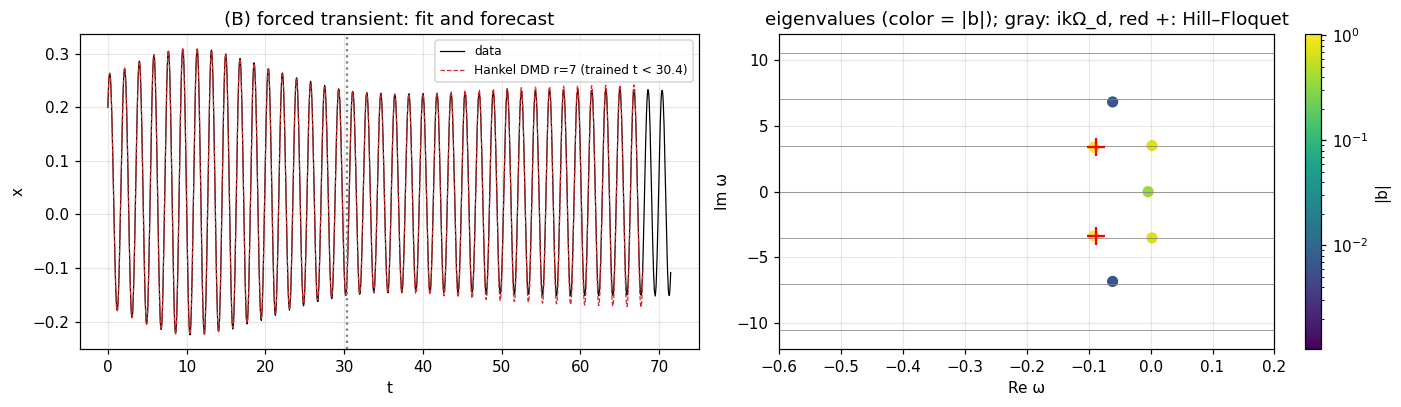

In [13]:
# 3-5. (B) 강제 과도 — 가진 고조파 + Floquet 지수, 학습 구간 밖 예측, Hill–Floquet 대조 -------------------------------------
dB = 64; ntrB = 32*15 + dB                                                   # 앞 15 주기로 학습
HB = hankel(xB[:ntrB], dB); sB = np.linalg.svd(HB[:, :-1], compute_uv=False); tauB, rB_svht = svht_rank(sB, HB.shape)
flA = pd.read_csv(DATA_DIR / "Q_20_DC_1_AC_0.19_Ω_0.7_HBM_coeffs_branch01_matlab_floquet_stability.csv"); rowA = flA.iloc[(flA.Omega - OmB).abs().argmin()]
fl_re, fl_im = np.log(rowA.mu1_abs)/TB, np.arctan2(rowA.mu1_im, rowA.mu1_re)/TB
print(f"Hankel d={dB}: SVHT r = {rB_svht} (σ_k/σ_1: {np.round(sB[:12]/sB[0], 4)})")
print(f"Hill–Floquet (연구 csv, Ω={rowA.Omega:.3f}): ω_F = {fl_re:.4f} ± {fl_im:.4f}i (mod iΩ_d={OdB:.3f}) → 격자점 {fl_re:.4f} ± {OdB - fl_im:.4f}i;  가진: ±{OdB:.4f}i (|λ|=1)")
rows = []
for r_ in sorted({rB_svht, 5, 9, 13}):
    D = hankel_dmd(xB[:ntrB], dB, r_, dtB); k = np.arange(nB+1 - dB + 1); xr = dmd_reconstruct(D, k)[0].real
    ef = np.linalg.norm(xr[:ntrB-dB] - xB[:ntrB-dB])/np.linalg.norm(xB[:ntrB-dB]); eo = np.linalg.norm(xr[ntrB-dB:] - xB[ntrB-dB:nB+2-dB])/np.linalg.norm(xB[ntrB-dB:nB+2-dB])
    jF = int(np.argmin(np.abs(D["omega"] - (fl_re + 1j*(OdB - fl_im))))); jD = int(np.argmin(np.abs(D["omega"] - 1j*OdB)))
    rows.append(dict(r=r_, fit_err=ef, forecast_err_25periods=eo, ω_forcing=f"{D['omega'][jD]:.4f}", abs_λ_forcing=abs(D["lam"][jD]), ω_Floquet=f"{D['omega'][jF]:.4f}"))
    if r_ == rB_svht: DB_ = D; xrB = xr
display(pd.DataFrame(rows).set_index("r"))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(tB, xB, "k", lw=0.8, label="data"); ax[0].plot(tB[:len(xrB)], xrB, "C3--", lw=0.8, label=f"Hankel DMD r={rB_svht} (trained t < {tB[ntrB]:.1f})"); ax[0].axvline(tB[ntrB], color="gray", ls=":"); ax[0].set_xlabel("t"); ax[0].set_ylabel("x"); ax[0].set_title("(B) forced transient: fit and forecast"); ax[0].legend(fontsize=8)
nrmB = np.linalg.norm(DB_["Phi"], axis=0); buB = np.abs(DB_["b"]*nrmB)
sc = ax[1].scatter(DB_["omega"].real, DB_["omega"].imag, c=buB, cmap="viridis", s=40, norm=plt.matplotlib.colors.LogNorm(buB.max()*1e-3, buB.max()))
for kk in range(-3, 4): ax[1].axhline(kk*OdB, color="gray", lw=0.5)
for sgn in (1, -1): ax[1].plot(fl_re, sgn*(OdB - fl_im), "r+", ms=12, mew=1.5)
ax[1].set_xlim(-0.6, 0.2); ax[1].set_ylim(-12, 12); ax[1].set_xlabel("Re ω"); ax[1].set_ylabel("Im ω"); ax[1].set_title("eigenvalues (color = |b|); gray: ikΩ_d, red +: Hill–Floquet"); plt.colorbar(sc, ax=ax[1], label="|b|")
plt.tight_layout(); plt.show()


**(B) 강제 과도 해석.**
* 고유값이 두 묶음으로 갈린다: **가진 고조파** $\pm ik\Omega_d$ ($|\lambda|\approx1$, 정상상태 파형)과 **Floquet 쌍** $-0.09\pm3.39i$ (과도의 감쇠, $\mathrm{Re}\,\omega=-c/2$) — 후자가 연구의 Hill–Floquet 승수에서 환산한 격자점 $-0.088\pm3.397i$와 맞는다. W06(eDMD)에서 본 구조가 센서 하나 + 지연좌표만으로도 나온다.
* 예측: 앞 15주기로 학습해 뒤 25주기를 외삽하면 오차 5–6 % — 오차의 대부분은 가진 고유값의 $|\lambda|$가 1에서 $10^{-4}$ 벗어나(잡음·절단 편향, 0.7의 "가짜 감쇠/성장") 25주기 동안 누적되는 진폭 drift다. $r$을 SVHT 값 근처로 두는 것이 가장 낫고, 더 키우면 잡음 방향이 들어와 예측이 나빠진다.
* 센서 하나의 강제 응답에서 "고유진동수·감쇠비"를 읽으려면 가진 성분을 먼저 가려내야 한다 — 표 0.3의 읽는 법($|\lambda|=1$인 것은 가진, $<1$인 켤레 쌍이 구조의 모드)으로 분리된다.

### 3-6. 요약과 한계
| 항목 | 결과 |
|---|---|
| 데이터 | CNT 공진기 시간 적분, 센서 1개 $x(t)$ + 잡음 $10^{-3}$: (A) 자유감쇠 소/대진폭 ($\Delta t=0.02$, 3000점), (B) 강제 과도 Ω=1.0 (Δt=T/32, 40주기) |
| 랭크 선택 | 지연좌표 $d=60$–64의 Hankel 특이값 + SVHT($\sigma_{\rm med}$ = 잡음 바닥): 작은 진폭 $r=3$(평균+켤레 쌍), 큰 진폭 4, 강제 7; $r$을 더 키우면 $\mathrm{Re}\,\omega\ll0$ 가짜 고유값 |
| 고유값 → 물리 | 작은 진폭: $\omega_n=3.412$, $\zeta=0.0257$ = 평형점 선형화 (정전기 연화로 $\omega_1=3.516$보다 3 % 낮음); 강제: 가진 $\pm i\Omega_d$ + Floquet $-0.088\pm3.397i$ = Hill–Floquet |
| 예측 | 작은 진폭 자유감쇠: 뒤 절반 외삽 0.026(= 잡음 수준); 큰 진폭: 0.27; 강제: 15주기 학습 → 25주기 외삽 0.055 (가진 $\lvert\lambda\rvert$ drift) |
| 한계 (0.9) | ① 센서 하나 → 지연좌표 필수(손계산 예 4); ② 큰 진폭의 진폭–주파수 의존 = 연속 스펙트럼 → 단일 $\omega$로는 평균만, 고조파·가짜 성장으로 메움; ③ 강제계·여러 끌개(isola, W06)는 끌개별로 따로 |
| 처방 | SVHT로 $r$ 고정 후 fbDMD/optDMD로 편향 보정; 큰 진폭은 진폭 구간별 창(mrDMD)·HAVOK(7주차); 방정식 자체는 SINDy(W04에서 이미 복원) |


## AI 사용 명세

사용 도구: Claude (Anthropic). 노트북 구성·코드 초안·문제 3의 설계(지연좌표, Floquet 대조) 논의에 사용했고, 아래는 질문 로그와 교재(식 번호)와 대조해 확인·수정한 지점이다. 코드는 모두 직접 실행해 수치를 확인했다.

### 1. 질문 로그 — 노트북 구성

| # | 질문 | 교재와 대조해 확인·수정한 지점 |
|---|---|---|
| 1 | W05 과제를 앞 주차와 같은 구성(정리 → 문제 → 코드 → 결과)의 .ipynb로; 문제 2는 제외; 개인 탐구는 내 데이터로. | 과제 요구(원기둥 $r=21$ 그림 5(b–d)·표, CVX 확인과 그림 1(b), 개인 탐구의 랭크·주파수/감쇠비·예측·한계)를 강의노트 17쪽과 대조. |
| 2 | `VORTALL.mat`(103 MB)은 어디서 받나? | databookuw.com DATA 또는 GitHub `dynamicslab/databook_python/DATA/VORTALL.mat`. 노트북은 폴더·`DATA/`·환경변수에서 찾고 없으면 1(b)를 건너뜀. |
| 3 | exact DMD의 진폭 $b$를 (7.31) $\Phi^\dagger x_1$ 대신 (7.32) $(W\Lambda)^{-1}\tilde x_1$로 계산해도 되나? | Code 7.3의 마지막 두 줄과 같음; $n\times r$ 의사역행렬을 피함. 모드를 단위 노름으로 정규화한 $|b|$로 노트의 291, 105, … 와 비교. |

### 2. 질문 로그 — 문제별 세부 질문과 확인 지점

**문제 1 (원기둥 후류·ℓ₁ 도구)**

| # | 질문 | 확인·수정한 지점 |
|---|---|---|
| 1-1 | MATLAB CVX의 설치 확인 출력을 Python 노트북에 어떻게 붙이나? | 노트북이 Θ, y를 .mat로 저장 → `w05_cvx_check.m`이 `cvx_version`을 찍고 CVX로 풀어 .mat로 반환 → 노트북이 읽어 같은 표·그림에 비교. MATLAB이 PATH에 있으면 `matlab -batch`로 자동 호출. |
| 1-2 | cvxpy·CVX가 없을 때 그림 1(b)를 어떻게 재현하나? | basis pursuit을 변수 분할 $s=u-v$로 LP(HiGHS)에 넘기면 CVX와 $10^{-7}$ 이내 같은 꼭짓점 해(손계산 예 1); ADMM은 투영+연임계화 반복으로 $10^{-3}$. |
| 1-3 | 특이값이 쌍으로 나오는 이유는? | 흘러가는 와류 = 진행파의 sin·cos 쌍(변수분리). 평균 모드만 홀로. |
| 1-4 | $f_1=0.1654$는 어떻게 읽나? | $\arg\lambda_1/(2\pi\Delta t)$ = 스트로할 수; 고조파는 정수배 — 비선형 상호작용의 흔적 [B&K 그림 7.3]. |
| 1-5 | 탐침 (2, 0.5)의 FFT와 DMD 진폭을 같은 축에 놓으려면? | 둘 다 $f_1$ 값으로 정규화; 격자 축은 교재 plotCylinder의 $x\in[-1,8]$, $y\in[-2,2]$로 가정. 앞 40점 FFT의 피크 0.125 vs DMD 0.1654 — DMD는 FFT 격자에 묶이지 않음. |
| 1-6 | 예측 오차(그림 5d)는 어떻게 정의하나? | 앞 100개로 학습한 $\Phi,\lambda,b$로 $k=1..151$을 재구성, 스냅샷별 $\|x_k-\hat x_k\|/\|x_k\|$; 101 이후가 예측. |
| 1-7 | 모드 그림에서 어느 열이 $f_1$인가? | `eig`의 정렬에 따라 다르므로 $f$로 찾음(노트 그림 6 캡션). |

**문제 3 (CNT 공진기 DMD)**

| # | 질문 | 확인·수정한 지점 |
|---|---|---|
| 3-1 | 센서가 하나인 데이터에 DMD를 바로 적용하면? | 스칼라 DMD는 실수 $\lambda$ 하나 — 진동 표현 불가(손계산 예 4, 노트 그림 9a) → Hankel 지연좌표 $d=60$. |
| 3-2 | 지연 수 $d$는 어떻게 정하나? | 최소 2(켤레 쌍), 잡음이 있으면 한 주기 이상(~30점)이 안정적; $d$를 바꿔도 SVHT $r$과 고유값이 같은지로 확인. |
| 3-3 | 잡음 없는 시뮬레이션에 SVHT를 쓰는 게 맞나? | 측정 잡음 $10^{-3}$을 더해 잡음 바닥을 만들고 SVHT가 그 위를 고르게 함(0.7); 잡음이 없으면 $\sigma_{\rm med}$가 반올림 수준이라 무의미(W02 D와 같은 주의). |
| 3-4 | DMD의 $\omega_n$이 $\omega_1=3.516$이 아니라 3.41인 이유는? | $V_{DC}$가 평형점을 $x_{eq}=0.04$로 당겨 정전기력의 기울기가 스프링을 연화 — 평형점 선형화 $k_{\rm eff}$로 확인(3.412). DMD가 틀린 게 아니라 물리. |
| 3-5 | 큰 진폭에서 DMD 주파수가 하나로 나오는데 믿어도 되나? | 영점 교차로 구한 순간 주파수가 진폭에 따라 변함(backbone) → 연속 스펙트럼(0.9). DMD는 평균값 + 가짜 성분. 예측 오차로 드러남. |
| 3-6 | 강제 응답에서 "구조의 고유진동수·감쇠비"는 어느 고유값인가? | $\lvert\lambda\rvert=1$인 것은 가진 고조파, $<1$인 켤레 쌍이 과도(Floquet). 그 쌍이 연구의 Hill–Floquet csv 격자점과 일치. |
| 3-7 | 강제 응답의 외삽 오차가 수 %인 원인은? | 가진 고유값의 $\lvert\lambda\rvert$가 1에서 $10^{-4}$ 벗어나 25주기 누적(가짜 성장/감쇠, 0.7의 편향). 처방: fbDMD·optDMD, 또는 $\lvert\lambda\rvert=1$ 강제. |
| 3-8 | 평균(DC 처짐)을 빼고 DMD해도 되나? | 빼지 않음(0.5): 평균 모드 $\lambda=1$이 $x_{eq}$를 담는다. 빼면 DFT 격자에 묶임. |
| 3-9 | W02(POD)·W04(SINDy)·W06(eDMD)과의 관계는? | 같은 계의 같은 식: W02는 파형의 차원, W04는 방정식 복원, W06은 상태+사전의 Koopman 근사, W05는 센서 하나의 시간 모델 — 표 0.10. |

### 3. AI 답변 중 틀렸거나 보완한 지점

| # | AI의 초기 답 | 수정 |
|---|---|---|
| 1 | 자유감쇠의 참 고유진동수를 $\omega_1=3.516$으로 두고 DMD 값 3.41을 "편향"으로 설명 | $V_{DC}$ 평형점 선형화를 계산하니 $\omega_n=3.412$ — DMD가 맞고 기준이 틀렸음. 정전기 연화로 정정(3-4). |
| 2 | 강제 응답 예측 오차의 원인을 "비선형성"으로 설명 | 가진 고유값 $\lvert\lambda\rvert$의 $10^{-4}$ drift가 누적되는 것임을 $r$별 표로 확인 → 편향 문제로 정정(3-7). |
| 3 | 1(b)의 탐침 FFT를 평균을 빼지 않고 계산 | DC 성분이 지배해 스펙트럼이 안 보임 → 평균을 뺀 FFT로 수정(DMD 자체는 평균을 빼지 않음). |
| 4 | 손계산 예 3의 exact 모드 $\Phi=X'V\Sigma^{-1}W$와 손계산 $\phi_\pm$가 다르다고 "불일치"로 적음 | 모드·진폭 규약 차이이고 곱 $\phi_jb_j$와 $x_4$는 같음(노트 손계산 예 3 마지막 줄) → 검산 출력으로 확인. |
